<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/QBoost_SmartCitySIEM_CICIoT2023_Barletta2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBoost for smart-city IoT intrusion detection on CICIoT2023: Barletta et al. (2024) step by step

This notebook re-implements, runs and checks the experiment of

> Vita Santa Barletta, Danilo Caivano, Mirko De Vincentiis, Anibrata Pal and Michele Scalera, "Hybrid quantum architecture for smart city security",
> *Journal of Systems and Software* 217 (2024) 112161. DOI 10.1016/j.jss.2024.112161

The paper proposes a *reference architecture* for a smart-city security operations centre that pairs a quantum intrusion detector (**QBoost** run as a QUBO on the D-Wave Leap
cloud) with a classical rule-based SIEM (**IBM QRadar**) behind one dashboard. The software architecture, the dashboard and the QRadar rules cannot be re-run (they need a
D-Wave account, a QRadar virtual machine and the raw packet captures). What *can* be re-run is the one quantitative experiment: **QBoost against Random Forest on the CICIoT2023
dataset** (accuracy / precision / recall / F1, Figure 17; training and prediction times, Table 1). The paper publishes no code.

**What the notebook does.**
1. Downloads a public, class-capped subsample of CICIoT2023 (1.43 million flows, 46 features, 34 labels) from a Hugging Face mirror.
2. Applies the paper's eight pre-processing steps (constant columns out, NaN/inf to the median, attack = +1 and normal = -1, `MinMaxScaler`, SMOTE + random under-sampling,
   PCA to 13 components, 80 : 20 split) with **every transform fitted on the training split only**.
3. Implements **QBoost** (a pool of 35 AdaBoost trees, a QUBO over which trees to keep, lambda = 0.085) and solves the QUBO with a **simulated-annealing sampler written here**
   (checked against exact enumeration), because the D-Wave Leap hybrid solver of the paper needs a paid cloud account.
4. Trains a **Random Forest** (the paper's comparison), plus an RBF-SVM, plain AdaBoost and a no-PCA reference on identical inputs.
5. Redraws Figure 17 and Table 1 next to the paper's numbers, runs ablations (lambda, number of PCA components, duplicate rows) and states a verdict for every claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. No quantum library is needed (QBoost is a QUBO; there is no gate circuit).
`FAST_MODE = True` (about 100,000 training flows, one seed) takes roughly 10 minutes; `FAST_MODE = False` uses the whole training split (about 1.14 million flows before
balancing) and three seeds (see the configuration cell for measured runtimes). The data are public; a Hugging Face token is **not** needed (if you ever point `HF_REPO` at a gated mirror,
put your own token in Colab *Secrets* under the name `HF_TOKEN`).

**What you get at the end.** A table of QBoost / Random Forest / AdaBoost / SVM results on a balanced and on a realistic test set, the paper's Figure 17 and Table 1 redrawn,
the QUBO that QBoost solves (couplings, selected trees, energy spectrum), and an honest list of which claims reproduce and which do not.

## The paper in one page

**Problem.** A smart city's IoT, mobility, government and environment sectors generate network traffic that must be screened for attacks. Rule-based SIEMs detect known patterns but
give no learning; ML detectors lack the attack path. The paper proposes a **hybrid architecture**: a Python/Flask *principal application* sends pre-processed flows to a quantum cloud
(D-Wave Leap, QBoost), receives "attack / normal", stores incidents in PostgreSQL, merges them with **IBM QRadar** offenses (hand-written rules for HTTP flood DDoS, XSS, SQL injection and
port scans) and shows both on an Angular dashboard (Figures 5 and 6).

**Decision.** Binary: normal (-1, `BenignTraffic`) against attack (+1, all 33 attack types merged).

**Method.** *QBoost* (Neven et al., 2012): a strong classifier is a subset of a pool of weak classifiers; choosing the subset is a QUBO solved on the QPU hybrid solver of `Advantage_system5.3`.
Hyper-parameter given: lambda = 0.085. Compared with a classical **Random Forest**.

**Data.** CICIoT2023 (Neto et al., 2023): 46,686,579 flows, 46 features, 34 labels (33 attacks + benign) from a 105-device IoT testbed; benign is only 2.3 %.

**Pre-processing (Section 5.2, eight steps).** (1) remove categorical features, (2) remove constant features, (3) NaN/inf -> median, (4) normal = -1 / attack = +1, (5) `MinMaxScaler`,
(6) balance with SMOTE (`sampling_strategy` 0.1, k = 7) then random under-sampling (`sampling_strategy` 0.8) -> **10,257,385 rows**, (7) PCA keeping 99 % of the variance -> **13 components**,
(8) 80 : 20 train/test split.

**Claims that can be checked.**
* Figure 17 / text: Random Forest accuracy **99 %**, QBoost **96 %**, "a margin of a mere 3 % for all quality metrics".
* Table 1: QBoost trains in **554.5 s** against Random Forest's **2667.5 s** (about **80 %** shorter) and predicts in **2.24 s** against **7.83 s** (about **71 %** shorter).
* PCA at a 0.99 variance threshold keeps **13** components.
* Not checkable here: the architecture, the dashboard (Figure 6), QRadar offenses and the 2 to 3 minute offense latency (Figures 8 to 16), the D-Wave hardware, absolute times on the authors' machine.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | full CICIoT2023: 46,686,579 rows, 169 CSV files, benign 2.3 % | Hugging Face mirror `lacg030175/CIC-IoT-2023-neto-subsample`: **1,429,753 rows**, same 46 features and 34 labels, a stratified subsample (benign 200,000 rows, each attack type up to 50,000 rows), derived from the official files. Benign is **14 %**, not 2.3 % (`# CHOICE`: the only public copy that is small enough to run in a class) |
| Categorical / constant columns | removed (counts not given) | Identical rule; the mirror has no categorical feature and one constant column (`Telnet`) |
| Missing values | NaN/inf -> median | Identical (medians from the training split; the mirror happens to contain none) |
| Split | 80 : 20 **after** balancing, so synthetic rows reach the test set | 80 : 20 stratified split provided by the mirror, taken **before** balancing; balancing touches the training split only (`# CHOICE`, avoids test leakage). The test set is reported twice: the *original* distribution and a *balanced* test set (benign : attack = 0.8, real rows only) that mimics the paper's balanced test |
| Scaling / PCA | `MinMaxScaler`, PCA(0.99) -> 13 components | Both fitted on the balanced training split. **13 components are used** as in the paper; the number that PCA(0.99) gives on this data is printed and compared (`# CHOICE`) |
| SMOTE | `sampling_strategy` 0.1, k = 7 | Same call, but only when the minority/majority ratio is below 0.1. In the mirror it is already 0.16, so SMOTE is **skipped** (imbalanced-learn would refuse a ratio below the current one) |
| Under-sampling | `sampling_strategy` 0.8 | Identical |
| Choosing balancing parameters | repeated stratified 10-fold x 3 on a Decision Tree | not repeated; the paper's final values are used directly |
| QBoost pool | not stated | `AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=35)`; its trees are the weak classifiers. 35 and depth 3 are the values of the same group's earlier QBoost paper (QC-023) (`# CHOICE`) |
| QBoost objective | lambda = 0.085, form not given | Neven's squared loss **averaged over the training samples** plus `lambda * (selected trees / pool size)` (`# CHOICE`: this normalisation makes lambda = 0.085 a moderate regulariser; the lambda sweep in Section 8 shows what other values do) |
| QUBO solver | D-Wave Leap hybrid solver on `Advantage_system5.3` | **Simulated annealing** written in numpy, 3000 reads, geometric temperature schedule (`# CHOICE`); validated against brute-force enumeration on a 16-variable instance |
| Random Forest | scikit-learn, hyper-parameters not given | `RandomForestClassifier()` with scikit-learn defaults (100 trees), single thread (`# CHOICE`) |
| Metrics | accuracy, precision, recall, F1 (averaging not stated; in the group's QC-023 paper recall equals accuracy, i.e. weighted) | accuracy and **weighted** precision / recall / F1, plus attack-class precision / recall / F1 |
| Seeds | not stated | `SEED = 42`; several seeds in the full run |
| Hardware | i7-11800H 32 GB, D-Wave Leap | a laptop CPU shared with other jobs or a Colab CPU runtime; times are comparable in order, not in size |
| QRadar rules, dashboard, REST API, PostgreSQL | implemented | not reproducible (no QRadar, no IPs in CICIoT2023 features); marked "cannot be checked" |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and (usually) imbalanced-learn / pyarrow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("imblearn", "pyarrow", "huggingface_hub", "sklearn") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "imbalanced-learn==0.14.2" "scikit-learn==1.9.1" pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("imbalanced-learn, pyarrow and huggingface_hub already present; skipping pip install.")

imbalanced-learn, pyarrow and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo, about 100,000 training flows, one seed, about 10 minutes on a CPU.
                            # False: the whole training split (1.14 M flows before balancing, about 360,000 balanced rows) and three seeds. Runtime measured here: FAST about 10 to 12 minutes;
                            # the full path was started on a CPU shared with other jobs and stopped after 30 minutes inside the first baseline cell (estimated well over 90 minutes), so
                            # the committed outputs come from FAST_MODE = True. On a free Colab CPU the full path should take roughly 1.5 to 2 hours.
SEED      = 42              # every random number generator is seeded from this
DATA_DIR  = "ciciot2023_data"   # downloaded data are cached here (a scratch folder, never committed)
HF_REPO   = "lacg030175/CIC-IoT-2023-neto-subsample"   # public mirror (no token needed); a gated mirror would need your own HF_TOKEN in Colab Secrets
LOCAL_TRAIN, LOCAL_TEST = "", ""   # optional: paths of manually downloaded train / test parquet files (skips the download)
IBM_TOKEN = ""              # unused: QBoost runs on D-Wave in the paper, no IBM device is involved in this experiment

# paper hyper-parameters (Section 5.2)
SMOTE_RATIO, SMOTE_K = 0.1, 7       # SMOTE sampling_strategy and k
RUS_RATIO            = 0.8          # random under-sampling sampling_strategy
N_PCA                = 13           # components kept after PCA (threshold 0.99 in the paper gives 13)
PCA_THRESHOLD        = 0.99
LAMBDA               = 0.085        # QBoost lambda
# our choices (the paper does not state them)
WEAK_CLASSIFIERS, TREE_DEPTH = 35, 3    # QBoost pool: size and depth of the trees (the same group's QC-023 paper)
SA_READS, SA_SWEEPS  = 3000, 200        # simulated-annealing reads (the D-Wave runs of the group use 3000) and sweeps per read
RF_TREES             = 100              # scikit-learn default

if FAST_MODE:
    TRAIN_ROWS_PRE = 100_000    # stratified pre-sample of the training split before balancing (None = whole split)
    SEEDS          = [SEED]
    SVC_CAP        = 2_000      # training rows of the RBF-SVM baseline
    ABL_ROWS       = 10_000     # training rows of the PCA-dimension ablation
else:
    TRAIN_ROWS_PRE = None
    SEEDS          = [SEED, SEED + 1, SEED + 2]
    SVC_CAP        = 5_000
    ABL_ROWS       = 40_000
print(f"FAST_MODE={FAST_MODE}  pre-sample={TRAIN_ROWS_PRE or 'whole training split'}  seeds={SEEDS}  QBoost: {WEAK_CLASSIFIERS} trees of depth {TREE_DEPTH}, lambda={LAMBDA}, SA reads={SA_READS}")

FAST_MODE=True  pre-sample=100000  seeds=[42]  QBoost: 35 trees of depth 3, lambda=0.085, SA reads=3000


In [3]:
import os, io, time, math, random, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
import sklearn, imblearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Hugging Face token (only needed if you switch HF_REPO to a gated mirror): environment variable or Colab Secrets, nowhere else
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

warnings.filterwarnings("ignore")
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("scikit-learn", sklearn.__version__, "| imbalanced-learn", imblearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2


## 1. The data: CICIoT2023

CICIoT2023 (Neto, Dadkhah, Ferreira, Zohourian, Lu, Ghorbani, *Sensors* 23(13), 2023) was recorded in a testbed of **105 IoT devices** (67 of them attacked) with Raspberry Pi
attackers: 33 attacks in seven families (DDoS, DoS, Recon, Web-based, Brute force, Spoofing, Mirai) plus benign traffic. Wireshark/`dpkt` captures were turned into **46 flow-level features**
(flag counts, protocol indicators, packet-size statistics, inter-arrival times, `Rate`, ...). The full release is 169 CSV files, 13.8 GB, 46.7 million rows, only 2.3 % benign - far too much
for a notebook.

The cell below downloads two public parquet files (train 60 MB, test 15 MB) from a Hugging Face **stratified subsample** of the official files (benign 200,000 rows, each attack type up to 50,000):
the same 46 features and labels, but with a much milder imbalance (benign 14 %). If the download is blocked, fetch the files by hand from the dataset page and put their paths in `LOCAL_TRAIN` / `LOCAL_TEST`.

In [4]:
FILES = {"train": "random/train-00000-of-00001.parquet", "test": "random/test-00000-of-00001.parquet"}

def fetch(split):
    """Return a local path of the parquet file of `split` (LOCAL_*, cache, huggingface_hub, then a plain HTTPS fallback)."""
    local = {"train": LOCAL_TRAIN, "test": LOCAL_TEST}[split]
    if local and os.path.exists(local):
        return local
    target = os.path.join(DATA_DIR, "hf", FILES[split])
    if os.path.exists(target) and os.path.getsize(target) > 1_000_000:
        return target
    try:
        from huggingface_hub import hf_hub_download
        return hf_hub_download(HF_REPO, FILES[split], repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf"), token=HF_TOKEN)
    except Exception as e:
        print("huggingface_hub failed (", repr(e)[:120], ") -> plain HTTPS fallback")
        os.makedirs(os.path.dirname(target), exist_ok=True)
        url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{FILES[split]}"
        r = requests.get(url, stream=True, timeout=120, headers={"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {})
        r.raise_for_status()
        with open(target, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
        return target

t0 = time.perf_counter()
df_tr = pd.read_parquet(fetch("train")); df_te = pd.read_parquet(fetch("test"))
print(f"downloaded + loaded in {time.perf_counter()-t0:.1f} s | train {df_tr.shape} | test {df_te.shape} | total rows {len(df_tr)+len(df_te):,}")
print("columns:", list(df_tr.columns))

downloaded + loaded in 1.3 s | train (1143802, 50) | test (285951, 50) | total rows 1,429,753
columns: ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'Label', 'Label_orig', 'attack_class', 'label']


## 2. Cleaning and labels, as in the paper

Steps (1) to (4) of the paper: drop categorical features, drop constant features, replace NaN/infinity by the median, and encode normal as -1 and attack as +1. The mirror carries four extra
bookkeeping columns (`Label`, `Label_orig`, `attack_class`, `label`) that are not features; `Label` is the original 34-valued label and `attack_class` the 8 families. Medians come from the training split only.

In [5]:
META = ["Label", "Label_orig", "attack_class", "label"]
feature_cols = [c for c in df_tr.columns if c not in META]
categorical = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(df_tr[c])]
constant = [c for c in feature_cols if c not in categorical and df_tr[c].nunique(dropna=True) <= 1]
kept = [c for c in feature_cols if c not in categorical and c not in constant]
print(f"features in the file: {len(feature_cols)} | categorical removed ({len(categorical)}): {categorical} | constant removed ({len(constant)}): {constant} | kept: {len(kept)}")

Xtr_raw = df_tr[kept].to_numpy(dtype=np.float32, copy=True); Xte_raw = df_te[kept].to_numpy(dtype=np.float32, copy=True)
n_bad_tr = int((~np.isfinite(Xtr_raw)).sum()); n_bad_te = int((~np.isfinite(Xte_raw)).sum())
print("NaN/inf values: train", n_bad_tr, "| test", n_bad_te)
Xtr_raw[~np.isfinite(Xtr_raw)] = np.nan; Xte_raw[~np.isfinite(Xte_raw)] = np.nan
medians = np.nanmedian(Xtr_raw, axis=0)                            # from the training split only
Xtr_raw = np.where(np.isnan(Xtr_raw), medians, Xtr_raw); Xte_raw = np.where(np.isnan(Xte_raw), medians, Xte_raw)

lab34_tr, lab34_te = df_tr["Label"].to_numpy(dtype=object), df_te["Label"].to_numpy(dtype=object)     # the 34 original labels
fam_tr, fam_te = df_tr["attack_class"].to_numpy(dtype=object), df_te["attack_class"].to_numpy(dtype=object)   # the 8 families
ytr = np.where(lab34_tr == "BenignTraffic", -1, 1); yte = np.where(lab34_te == "BenignTraffic", -1, 1)       # normal -> -1, attack -> +1 (the paper's labels)
assert (ytr == np.where(df_tr["label"].to_numpy() == 1, 1, -1)).all(), "binary label differs from the mirror's own label column"
print("binary counts, train (-1 normal / +1 attack):", {int(k): int(v) for k, v in zip(*np.unique(ytr, return_counts=True))}, "| test:", {int(k): int(v) for k, v in zip(*np.unique(yte, return_counts=True))})
print(f"benign share: {np.mean(ytr==-1):.3%} in this mirror (the paper's full dataset: 2.3 %)")
del df_tr, df_te

features in the file: 46 | categorical removed (0): [] | constant removed (1): ['Telnet'] | kept: 45


NaN/inf values: train 0 | test 0


binary counts, train (-1 normal / +1 attack): {-1: 160000, 1: 983802} | test: {-1: 40000, 1: 245951}
benign share: 13.988% in this mirror (the paper's full dataset: 2.3 %)


## 3. Scaling, balancing, PCA, evaluation sets (every transform fitted on the training split only)

Steps (5) to (8). The mirror's 80 : 20 split (stratified on the binary label) is kept, and **only the training split is balanced** (SMOTE then random under-sampling with the paper's parameters). The test split is
used twice: as it is (*original distribution*, 16 % normal flows), and under-sampled to the same normal : attack = 0.8 ratio as the paper's balanced data, using real rows only (*balanced test*). PCA is fitted on the balanced
training split with all components; the first 13 are used, and the number of components that a 0.99 variance threshold would give is reported and compared with the paper's 13.

`prepare(seed)` does all of this and is called once per seed; the seed controls the pre-sampling, SMOTE, under-sampling and the balanced test selection.

In [6]:
scaler = MinMaxScaler().fit(Xtr_raw)                                      # fitted on the training split
Xs_tr = scaler.transform(Xtr_raw).astype(np.float32); Xs_te = np.clip(scaler.transform(Xte_raw), 0, 1).astype(np.float32)
del Xtr_raw, Xte_raw

def stratified_idx(n, labels, seed):
    """Indices of a stratified random sample of size n (all indices when n is None or too large)."""
    if n is None or n >= len(labels):
        return np.arange(len(labels))
    keep, _ = train_test_split(np.arange(len(labels)), train_size=n, stratify=labels, random_state=seed)
    return np.sort(keep)

def prepare(seed):
    """Balance the training split (SMOTE if needed, then RUS), fit PCA on it, project train and test. Returns a dict."""
    pre = stratified_idx(TRAIN_ROWS_PRE, lab34_tr, seed)
    Xa, ya = Xs_tr[pre], ytr[pre]
    ratio = (ya == -1).sum() / (ya == 1).sum()
    info = {"pre_rows": len(pre), "ratio_before": ratio, "smote": False}
    if ratio < SMOTE_RATIO:                                                   # the paper's SMOTE call; only valid when the minority is below 0.1 of the majority
        Xa, ya = SMOTE(sampling_strategy=SMOTE_RATIO, k_neighbors=SMOTE_K, random_state=seed).fit_resample(Xa, ya)
        info["smote"] = True
    ib = RandomUnderSampler(sampling_strategy=RUS_RATIO, random_state=seed).fit_resample(np.arange(len(ya)).reshape(-1, 1), ya)[0].ravel()
    Xb, yb = Xa[ib], ya[ib]
    info.update(rows_balanced=len(yb), ratio_after=(yb == -1).sum() / (yb == 1).sum(), n_normal=int((yb == -1).sum()), n_attack=int((yb == 1).sum()))
    pca = PCA(n_components=None, random_state=seed).fit(Xb)                   # all components; the first N_PCA are used
    cum = np.cumsum(pca.explained_variance_ratio_)
    info["n_pca_threshold"] = int(np.searchsorted(cum, PCA_THRESHOLD, side="right") + 1)
    Pb, Pte = pca.transform(Xb), pca.transform(Xs_te)
    ibt = RandomUnderSampler(sampling_strategy=RUS_RATIO, random_state=seed).fit_resample(np.arange(len(yte)).reshape(-1, 1), yte)[0].ravel()
    return dict(Xb=Xb, yb=yb, Pb=Pb, Pte=Pte, te_bal=np.sort(ibt), pca=pca, cum=cum, info=info, pre=pre)

t0 = time.perf_counter()
D = prepare(SEED)
I = D["info"]
print(f"prepared in {time.perf_counter()-t0:.1f} s")
print(f"training rows before balancing: {I['pre_rows']:,} (normal/attack = {I['ratio_before']:.3f}) | SMOTE applied: {I['smote']} "
      f"(the paper's SMOTE ratio {SMOTE_RATIO} is below the mirror's {I['ratio_before']:.3f}, so there is nothing to oversample)")
print(f"after under-sampling at {RUS_RATIO}: {I['rows_balanced']:,} rows = {I['n_normal']:,} normal + {I['n_attack']:,} attack (ratio {I['ratio_after']:.3f}); the paper's balanced data: 10,257,385 rows")
print(f"PCA: variance of the first {N_PCA} components = {D['cum'][N_PCA-1]:.4f} | components needed for {PCA_THRESHOLD:.0%}: {I['n_pca_threshold']} (paper: 13)")
print(f"test split: {len(yte):,} rows original | {len(D['te_bal']):,} rows balanced test (normal {int((yte[D['te_bal']]==-1).sum()):,} / attack {int((yte[D['te_bal']]==1).sum()):,})")

prepared in 12.9 s
training rows before balancing: 100,000 (normal/attack = 0.163) | SMOTE applied: False (the paper's SMOTE ratio 0.1 is below the mirror's 0.163, so there is nothing to oversample)
after under-sampling at 0.8: 31,473 rows = 13,988 normal + 17,485 attack (ratio 0.800); the paper's balanced data: 10,257,385 rows
PCA: variance of the first 13 components = 0.9759 | components needed for 99%: 16 (paper: 13)
test split: 285,951 rows original | 90,000 rows balanced test (normal 40,000 / attack 50,000)


## Dataset Exploration and Visualisation

Everything below uses the real CICIoT2023 flows: shape, feature names, the original 34 labels and 8 families with their counts, and 2-D pictures of real training flows coloured by their true
label. The scatter plots use the first principal components of the PCA that QBoost actually receives (fitted on the balanced training split). QBoost does not use angle encoding (its inputs are compared
with decision-tree thresholds, not turned into rotation angles), so no extra [0, pi] rescaling is shown.

dataset shape: train (1143802, 45) | test (285951, 45) (rows, features); total 1,429,753 rows (full CICIoT2023 has 46,686,579)

45 features used (min-max scaled): ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight']
dropped constant feature(s): ['Telnet']

original label values and counts (train + test), 34 labels:


BenignTraffic              200000
DDoS-ACK_Fragmentation      50000
DNS_Spoofing                50000
MITM-ArpSpoofing            50000
DDoS-UDP_Fragmentation      50000
DoS-HTTP_Flood              50000
DDoS-ICMP_Fragmentation     50000
DoS-UDP_Flood               50000
DoS-TCP_Flood               50000
DDoS-PSHACK_Flood           50000
DDoS-RSTFINFlood            50000
DDoS-ICMP_Flood             50000
DDoS-UDP_Flood              50000
Recon-OSScan                50000
DDoS-TCP_Flood              50000
Recon-HostDiscovery         50000
DoS-SYN_Flood               50000
Mirai-greip_flood           50000
Mirai-greeth_flood          50000
DDoS-SYN_Flood              50000
Mirai-udpplain              50000
DDoS-SynonymousIP_Flood     50000
Recon-PortScan              50000
VulnerabilityScan           37382
DDoS-HTTP_Flood             28790
DDoS-SlowLoris              23426
DictionaryBruteForce        13064
BrowserHijacking             5859
CommandInjection             5409
SqlInjection  


families (8):


DDoS          552216
Benign        200000
DoS           200000
Recon         189644
Mirai         150000
Spoofing      100000
Web-based      24829
BruteForce     13064


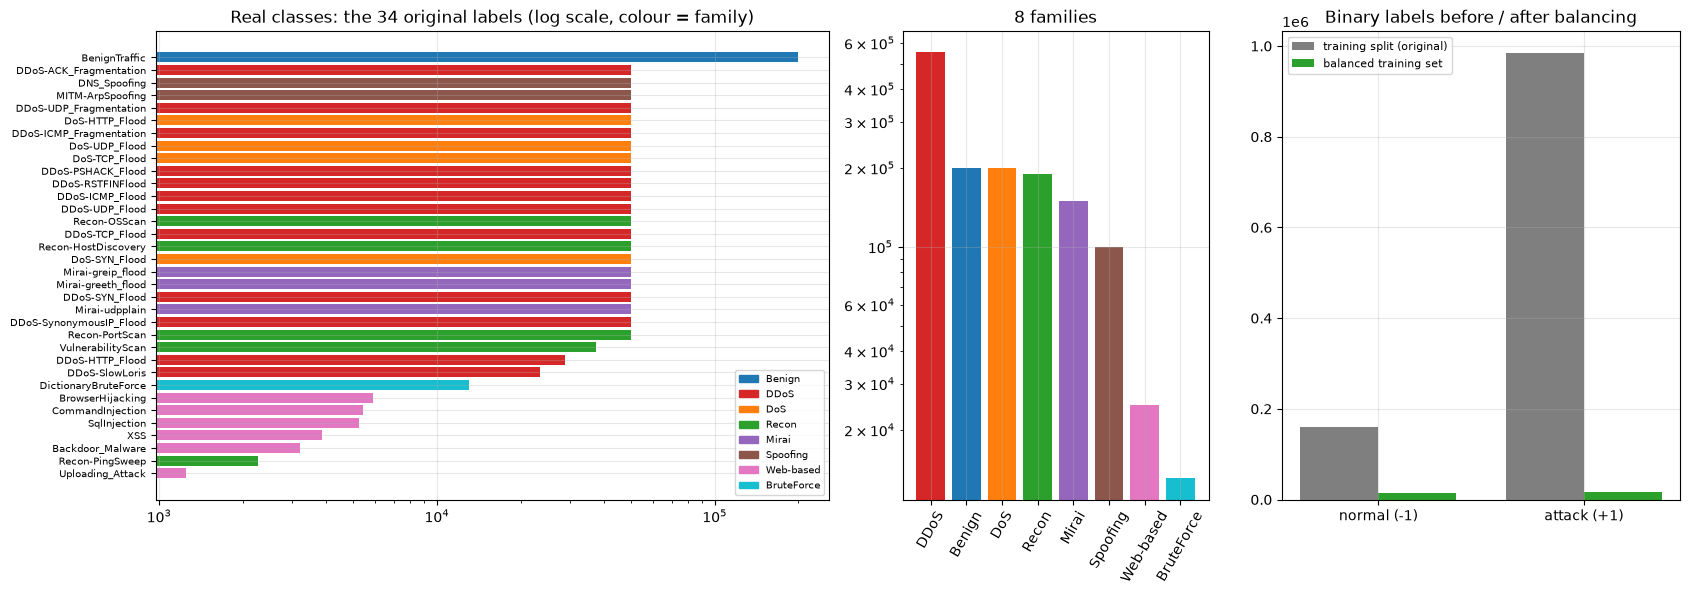

In [7]:
print("dataset shape: train", Xs_tr.shape, "| test", Xs_te.shape, "(rows, features); total", f"{len(ytr)+len(yte):,}", "rows (full CICIoT2023 has 46,686,579)")
print(f"\n{len(kept)} features used (min-max scaled): {kept}")
print("dropped constant feature(s):", constant)
print("\noriginal label values and counts (train + test), 34 labels:")
lab_all = np.concatenate([lab34_tr, lab34_te]); fam_all = np.concatenate([fam_tr, fam_te])
lab_counts = pd.Series(lab_all).value_counts()
print(lab_counts.to_string())
fam_of = pd.Series(fam_all, index=lab_all).groupby(level=0).first()
print("\nfamilies (8):"); print(pd.Series(fam_all).value_counts().to_string())

FAM_COLORS = {"Benign": "#1f77b4", "DDoS": "#d62728", "DoS": "#ff7f0e", "Recon": "#2ca02c", "Mirai": "#9467bd", "Spoofing": "#8c564b", "Web-based": "#e377c2", "BruteForce": "#17becf"}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2), gridspec_kw={"width_ratios": [2.2, 1, 1.3]})
order = lab_counts.index[::-1]
axes[0].barh(order, lab_counts[order].values, color=[FAM_COLORS[fam_of[l]] for l in order]); axes[0].set_xscale("log")
axes[0].set_title("Real classes: the 34 original labels (log scale, colour = family)"); axes[0].tick_params(axis="y", labelsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COLORS.values()]; axes[0].legend(handles, FAM_COLORS.keys(), fontsize=7, loc="lower right")
fc = pd.Series(fam_all).value_counts()
axes[1].bar(fc.index, fc.values, color=[FAM_COLORS[k] for k in fc.index]); axes[1].set_yscale("log"); axes[1].tick_params(axis="x", rotation=60)
axes[1].set_title("8 families")
b_before = pd.Series(ytr).map({-1: "normal", 1: "attack"}).value_counts(); b_after = pd.Series(D["yb"]).map({-1: "normal", 1: "attack"}).value_counts()
xs = np.arange(2); w = 0.38
axes[2].bar(xs - w/2, [b_before["normal"], b_before["attack"]], w, label="training split (original)", color="#7f7f7f")
axes[2].bar(xs + w/2, [b_after["normal"], b_after["attack"]], w, label="balanced training set", color="#2ca02c")
axes[2].set_xticks(xs); axes[2].set_xticklabels(["normal (-1)", "attack (+1)"]); axes[2].legend(fontsize=8); axes[2].set_title("Binary labels before / after balancing")
plt.tight_layout(); plt.show()

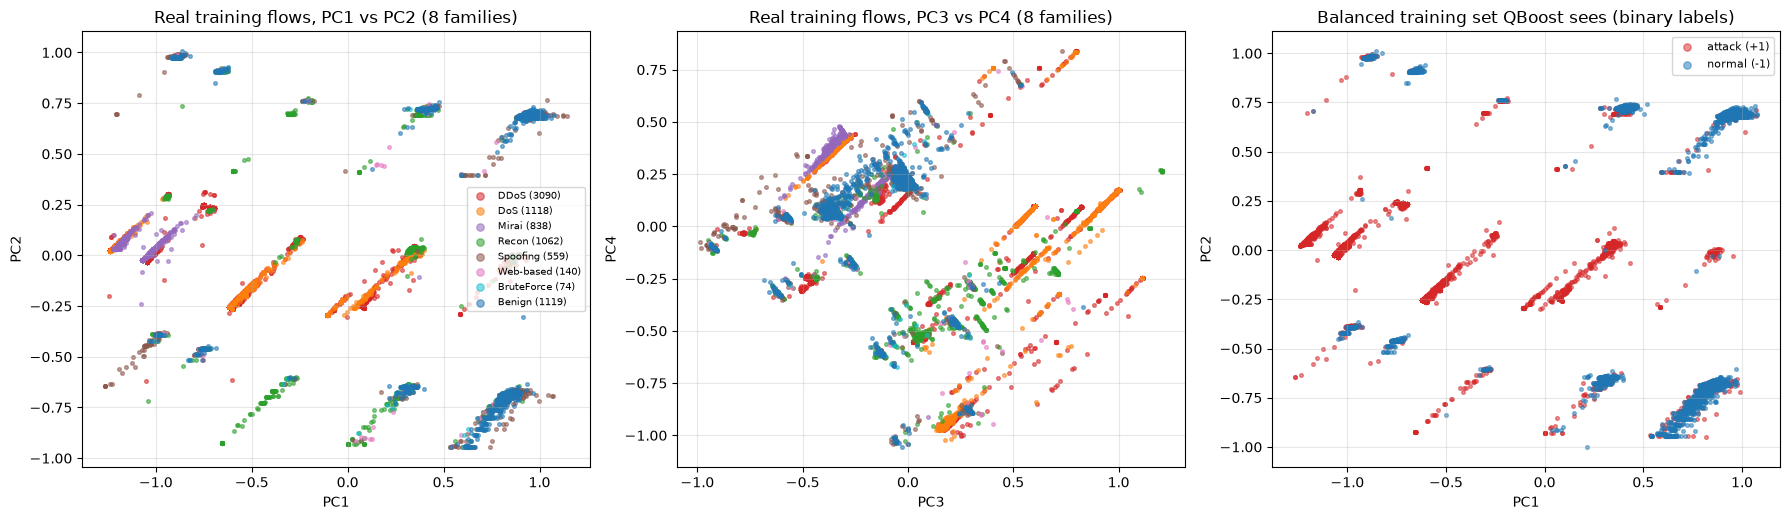

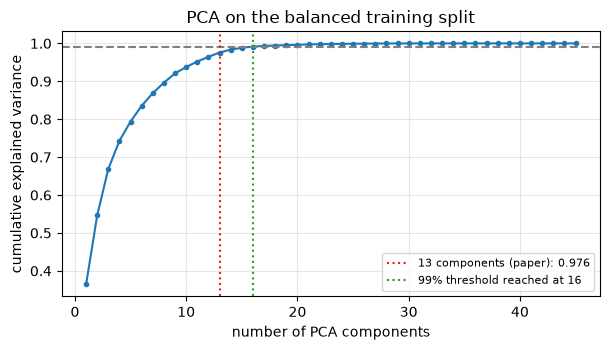

Reading the scatter: the real flows form a few dense blobs and long streaks; attack families overlap with each other and with normal traffic in the first two components, so a classifier needs more than 2 components.


In [8]:
# 2-D scatter of REAL training flows coloured by their ground-truth family: PCA coordinates fitted on the balanced training split
pca_main = D["pca"]
show = stratified_idx(8000, lab34_tr, SEED)                                    # 8000 real training flows, stratified by the 34 labels
Ps = pca_main.transform(Xs_tr[show]); fs = fam_tr[show]
draw_order = ["DDoS", "DoS", "Mirai", "Recon", "Spoofing", "Web-based", "BruteForce", "Benign"]        # Benign drawn last so that it stays visible
fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for ax, (a, b) in zip(axes[:2], [(0, 1), (2, 3)]):
    for f in draw_order:
        m = fs == f
        ax.scatter(Ps[m, a], Ps[m, b], s=7, alpha=0.55, color=FAM_COLORS[f], label=f"{f} ({m.sum()})")
    ax.set_xlabel(f"PC{a+1}"); ax.set_ylabel(f"PC{b+1}"); ax.set_title(f"Real training flows, PC{a+1} vs PC{b+1} (8 families)")
axes[0].legend(fontsize=7, markerscale=2)
Pb2 = D["Pb"]; sb = stratified_idx(8000, D["yb"], SEED)
for yv, nm, c in [(1, "attack (+1)", "#d62728"), (-1, "normal (-1)", "#1f77b4")]:
    m = D["yb"][sb] == yv
    axes[2].scatter(Pb2[sb][m, 0], Pb2[sb][m, 1], s=7, alpha=0.5, color=c, label=nm)
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].legend(fontsize=8, markerscale=2); axes[2].set_title("Balanced training set QBoost sees (binary labels)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(np.arange(1, len(D["cum"]) + 1), D["cum"], "o-", ms=3)
ax.axhline(PCA_THRESHOLD, color="gray", ls="--"); ax.axvline(N_PCA, color="#d62728", ls=":", label=f"{N_PCA} components (paper): {D['cum'][N_PCA-1]:.3f}")
ax.axvline(D["info"]["n_pca_threshold"], color="#2ca02c", ls=":", label=f"{PCA_THRESHOLD:.0%} threshold reached at {D['info']['n_pca_threshold']}")
ax.set_xlabel("number of PCA components"); ax.set_ylabel("cumulative explained variance"); ax.set_title("PCA on the balanced training split"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Reading the scatter: the real flows form a few dense blobs and long streaks; attack families overlap with each other and with normal traffic in the first two components, so a classifier needs more than 2 components.")

## Quantum Circuit Architecture

NOT_APPLICABLE: QBoost is not a gate-based circuit model. The weak classifiers are classical decision trees; the quantum part of the paper is the *quantum annealing* of a 35-variable QUBO on a D-Wave QPU
(the Ising Hamiltonian of Eq. (1) to (4) in Section 3.2), which has no gate circuit, depth or trainable gate parameters. This notebook replaces the annealer by a classical simulated-annealing sampler; the QUBO that is annealed
(couplings, linear terms, selected trees and the energy spectrum of the samples) is drawn in Section 7.

## 4. Metrics and classical baselines on identical inputs

Metrics as in Figure 17 of the paper: accuracy and (weighted) precision, recall, F1; we add the attack-class values (attack = positive class). Every model is scored on the *original* test split and on the *balanced* test
subset, and its training and prediction wall-clock times are recorded (prediction time = time to label the whole original test split, `len(y_test)` flows).

Baselines, all on the identical 13 PCA components: **Random Forest** (the paper's comparison, scikit-learn defaults), an **RBF-SVM** trained on a capped sample of the training rows, plain **AdaBoost** with the same pool as QBoost
(it votes with its learned weights, so it shows what QBoost's subset selection adds or loses), and, as a reference, a **Random Forest on all scaled features without PCA**.

In [9]:
def metrics(y_true, y_pred):
    a = accuracy_score(y_true, y_pred)
    pw, rw, fw, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    pa, ra, fa, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return dict(acc=a, prec_w=pw, rec_w=rw, f1_w=fw, prec_att=pa, rec_att=ra, f1_att=fa)

RESULTS, PRED = [], {}                 # RESULTS: one row per (model, seed, test set); PRED: test predictions of the first seed (confusion matrices)
def record(model, seed, pred_te, te_bal, t_train, t_pred, n_train, **extra):
    for tset, idx in (("original", slice(None)), ("balanced", te_bal)):
        RESULTS.append(dict(model=model, seed=seed, test=tset, t_train=t_train, t_pred=t_pred, n_train=n_train, **metrics(yte[idx], pred_te[idx]), **extra))
    if seed == SEEDS[0]:
        PRED[model] = (pred_te, te_bal)

def run_classical(D, seed):
    Pb, yb, Pte, te_bal = D["Pb"][:, :N_PCA], D["yb"], D["Pte"][:, :N_PCA], D["te_bal"]
    t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=RF_TREES, random_state=seed).fit(Pb, yb); t_tr = time.perf_counter() - t0
    t0 = time.perf_counter(); p = rf.predict(Pte); t_pr = time.perf_counter() - t0
    record("Random Forest", seed, p, te_bal, t_tr, t_pr, len(yb)); del rf
    ii = stratified_idx(SVC_CAP, yb, seed)
    t0 = time.perf_counter(); svc = SVC(kernel="rbf").fit(Pb[ii], yb[ii]); t_tr = time.perf_counter() - t0
    t0 = time.perf_counter(); p = svc.predict(Pte); t_pr = time.perf_counter() - t0
    record("SVC (RBF)", seed, p, te_bal, t_tr, t_pr, len(ii))
    if seed == SEEDS[0]:                                                       # reference: no PCA, all scaled features
        t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=RF_TREES, random_state=seed).fit(D["Xb"], yb); t_tr = time.perf_counter() - t0
        t0 = time.perf_counter(); p = rf.predict(Xs_te); t_pr = time.perf_counter() - t0
        record("Random Forest (no PCA, all features)", seed, p, te_bal, t_tr, t_pr, len(yb)); del rf

t0 = time.perf_counter()
run_classical(D, SEED)
print(f"classical baselines (seed {SEED}) in {time.perf_counter()-t0:.0f} s")
pd.DataFrame(RESULTS).query("test=='balanced'")[["model", "acc", "prec_w", "rec_w", "f1_w", "t_train", "t_pred"]].round(4)

classical baselines (seed 42) in 193 s


,model,acc,prec_w,rec_w,f1_w,t_train,t_pred
1,Random Forest,0.9102,0.9153,0.9102,0.9105,54.2150,15.9358
3,SVC (RBF),0.8907,0.9072,0.8907,0.8909,0.3341,72.5812
5,"Random Forest (no PCA, all features)",0.9690,0.9696,0.9690,0.9691,35.6813,12.7553


## 5. QBoost: boosting as a QUBO

**The algorithm (Neven et al., 2008 and 2012).** Train a pool of $N$ weak classifiers $h_i(x) \in \{-1,+1\}$ (here the 35 depth-3 trees of an AdaBoost run; this is also what D-Wave's open-source QBoost example does).
A strong classifier is a subset of the pool, written as binary weights $w_i \in \{0,1\}$, with decision $H(x) = \operatorname{sign}\big(\tfrac1N\sum_i w_i h_i(x)\big)$. The subset is chosen by minimising

$$E(w) = \frac1S\sum_{s=1}^{S}\Big(\tfrac1N\sum_i w_i h_i(x_s) - y_s\Big)^2 + \frac{\lambda}{N}\sum_i w_i ,\qquad \lambda = 0.085,$$

which, expanded with $w_i^2 = w_i$, is a QUBO: linear terms $b_i = \tfrac1{SN^2}\sum_s h_i(x_s)^2 - \tfrac{2}{SN}\sum_s h_i(x_s)y_s + \tfrac{\lambda}{N}$ and couplings $J_{ij} = \tfrac{2}{SN^2}\sum_s h_i(x_s)h_j(x_s)$.
The paper hands this QUBO to the D-Wave hybrid solver. Here it is solved by **simulated annealing**: 3000 independent annealing runs ("reads"), each flipping the 35 bits with Metropolis probabilities while the temperature falls geometrically;
the lowest-energy read is kept. A QPU explores the same energy landscape by quantum annealing. Auto-scaling and spin-reversal transforms are QPU hardware options with no classical counterpart.

*Honest caveat:* the paper's QBoost numbers come from a D-Wave machine; here the same optimisation problem is solved classically, so this notebook tests the **QUBO formulation, its hyper-parameters and the claim that the resulting classifier is
close to a Random Forest**, not the annealer. With 35 binary variables the problem is tiny; the check below against exact enumeration shows that the sampler finds the true optimum.

In [10]:
def build_qubo(H, y, lam):
    """QUBO (b, J) of the QBoost energy. H: pool x S matrix of weak outputs already divided by the pool size N; y in {-1,+1}.
    E(w) = sum_i b_i w_i + sum_{i<j} J_ij w_i w_j + const;  # CHOICE: squared loss averaged over S, penalty lam/N per selected tree."""
    N, S = H.shape
    G = H @ H.T / S
    b = np.diag(G) - 2.0 * (H @ y) / S + lam / N        # w_i^2 = w_i: the diagonal of the Gram matrix joins the linear terms
    J = 2.0 * (G - np.diag(np.diag(G)))                 # symmetric matrix, J_ij = J_ji; energy uses 0.5 * w J w = sum_{i<j} J_ij w_i w_j
    return b, J

def qubo_energy(b, J, W):
    """Energies of a batch of binary vectors W (reads x N)."""
    return W @ b + 0.5 * np.einsum("ri,ri->r", W @ J, W)

def anneal_qubo(b, J, reads=3000, sweeps=200, seed=0):
    """Simulated annealing on a QUBO: `reads` independent runs in parallel (vectorised), geometric temperature schedule.
    # CHOICE: T0 = 0.3 x energy scale, T1 = 1e-4 x energy scale (ours; the paper used D-Wave's hybrid solver)."""
    r = np.random.default_rng(seed)
    N = len(b)
    W = (r.random((reads, N)) < 0.5).astype(np.float64)
    F = W @ J                                           # local fields
    scale = np.abs(b).max() + np.abs(J).sum(1).max()
    T0, T1 = 0.3 * scale, 1e-4 * scale
    for sw in range(sweeps):
        T = T0 * (T1 / T0) ** (sw / max(sweeps - 1, 1))
        for i in r.permutation(N):
            dE = (1.0 - 2.0 * W[:, i]) * (b[i] + F[:, i])
            accept = (dE <= 0) | (r.random(reads) < np.exp(-np.clip(dE, 0, None) / T))
            d = np.where(accept, 1.0 - 2.0 * W[:, i], 0.0)
            W[:, i] += d
            F += np.outer(d, J[i])
    E = qubo_energy(b, J, W)
    k = int(np.argmin(E))
    return W[k], E, W

# ---- validation of the solver on a 16-variable instance: exact enumeration (65,536 states) against simulated annealing
Pb_, yb_ = D["Pb"][:, :N_PCA], D["yb"]
ii_ = stratified_idx(5000, yb_, SEED)
_ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=TREE_DEPTH), n_estimators=16, random_state=SEED).fit(Pb_[ii_], yb_[ii_])
_H = np.array([t.predict(Pb_[ii_]) for t in _ada.estimators_], dtype=float) / 16
_b, _J = build_qubo(_H, yb_[ii_].astype(float), LAMBDA)
_all = ((np.arange(2 ** 16)[:, None] >> np.arange(16)) & 1).astype(float)
_E = qubo_energy(_b, _J, _all)
_w, _Es, _ = anneal_qubo(_b, _J, reads=200, sweeps=100, seed=SEED)
print(f"exact minimum {_E.min():.8f} | simulated annealing, best of 200 reads {_Es.min():.8f} | same optimum: {np.isclose(_E.min(), _Es.min())}")
assert np.isclose(_E.min(), _Es.min()), "annealer did not find the exact optimum on the validation instance"
# the expanded QUBO equals the original objective up to the constant mean(y^2)
_w0 = _all[12345]; _ys = yb_[ii_].astype(float)
_direct = np.mean((_w0 @ _H - _ys) ** 2) + LAMBDA / 16 * _w0.sum()
print("QUBO energy + mean(y^2) equals the original QBoost objective:", np.isclose(qubo_energy(_b, _J, _w0[None])[0] + np.mean(_ys ** 2), _direct))
del _all, _E

exact minimum -0.38216875 | simulated annealing, best of 200 reads -0.38216875 | same optimum: True
QUBO energy + mean(y^2) equals the original QBoost objective: True


In [11]:
def qboost_fit(Pa, ya, seed, lam=LAMBDA, reads=SA_READS, sweeps=SA_SWEEPS, pool_model=None):
    """Train QBoost on (Pa, ya): AdaBoost pool, QUBO, simulated annealing. Returns the fitted pieces and timings."""
    t0 = time.perf_counter()
    ada = pool_model or AdaBoostClassifier(DecisionTreeClassifier(max_depth=TREE_DEPTH), n_estimators=WEAK_CLASSIFIERS, random_state=seed).fit(Pa, ya)
    pool = ada.estimators_[:WEAK_CLASSIFIERS]
    t_pool = time.perf_counter() - t0
    H = np.array([t.predict(Pa) for t in pool], dtype=np.float32) / len(pool)         # weak outputs scaled by 1/N
    t1 = time.perf_counter()
    b, J = build_qubo(H.astype(np.float64), ya.astype(float), lam)
    w, E, Wall = anneal_qubo(b, J, reads=reads, sweeps=sweeps, seed=seed)
    t_sa = time.perf_counter() - t1
    return dict(ada=ada, pool=pool, w=w, E=E, Wall=Wall, b=b, J=J, t_train=time.perf_counter() - t0, t_pool=t_pool, t_sa=t_sa)

def qboost_predict(m, P, w=None):
    w = m["w"] if w is None else w
    Ht = np.array([t.predict(P) for t in m["pool"]], dtype=np.float32) / len(m["pool"])
    return np.where(w @ Ht >= 0, 1, -1), Ht

def run_qboost(D, seed):
    Pb, yb, Pte, te_bal = D["Pb"][:, :N_PCA], D["yb"], D["Pte"][:, :N_PCA], D["te_bal"]
    m = qboost_fit(Pb, yb, seed)
    t0 = time.perf_counter(); pred, Ht = qboost_predict(m, Pte); t_pr = time.perf_counter() - t0
    record("QBoost (SA solver)", seed, pred, te_bal, m["t_train"], t_pr, len(yb), n_selected=int(m["w"].sum()), t_pool=m["t_pool"], t_sa=m["t_sa"])
    t0 = time.perf_counter(); pa = m["ada"].predict(Pte); t_pa = time.perf_counter() - t0                  # plain AdaBoost: same pool, its own learned weights
    record("AdaBoost (same pool)", seed, pa, te_bal, m["t_pool"], t_pa, len(yb))
    return m, Ht

t0 = time.perf_counter()
QB, HT_TEST = run_qboost(D, SEED)
print(f"QBoost (seed {SEED}) in {time.perf_counter()-t0:.0f} s: pool training {QB['t_pool']:.1f} s, QUBO + simulated annealing {QB['t_sa']:.1f} s, "
      f"{int(QB['w'].sum())} of {WEAK_CLASSIFIERS} trees selected, best energy {QB['E'].min():.5f}, "
      f"{np.mean(np.isclose(QB['E'], QB['E'].min())):.1%} of the {SA_READS} reads reached it")
pd.DataFrame(RESULTS).query("test=='balanced'")[["model", "acc", "prec_w", "rec_w", "f1_w", "t_train", "t_pred"]].round(4)

QBoost (seed 42) in 60 s: pool training 26.4 s, QUBO + simulated annealing 20.6 s, 27 of 35 trees selected, best energy -0.38300, 99.9% of the 3000 reads reached it


,model,acc,prec_w,rec_w,f1_w,t_train,t_pred
1,Random Forest,0.9102,0.9153,0.9102,0.9105,54.2150,15.9358
3,SVC (RBF),0.8907,0.9072,0.8907,0.8909,0.3341,72.5812
5,"Random Forest (no PCA, all features)",0.9690,0.9696,0.9690,0.9691,35.6813,12.7553
7,QBoost (SA solver),0.8879,0.9097,0.8879,0.8879,47.5303,5.5733
9,AdaBoost (same pool),0.8967,0.9071,0.8967,0.8969,26.3748,5.6246


## 6. More seeds

The full run repeats pre-sampling, balancing, PCA, the pool, the annealing and the forest for further seeds, so the table below reports mean and standard deviation. In FAST mode only one seed is run and the std column is empty.

In [12]:
t0 = time.perf_counter()
for sd in SEEDS[1:]:
    D_s = prepare(sd)
    run_classical(D_s, sd)
    run_qboost(D_s, sd)
    del D_s
print(f"extra seeds {SEEDS[1:]} done in {time.perf_counter()-t0:.0f} s")
res = pd.DataFrame(RESULTS)
cols = ["acc", "prec_w", "rec_w", "f1_w", "prec_att", "rec_att", "f1_att", "t_train", "t_pred"]
summ = res.groupby(["test", "model"])[cols].agg(["mean", "std"]).round(4)
for t in ("balanced", "original"):
    print(f"\n=== {t} test set ({'normal : attack = 0.8, real rows only' if t == 'balanced' else 'the untouched test split'}); mean and std over {len(SEEDS)} seed(s) ===")
    print(summ.loc[t][[(c, s) for c in cols[:4] for s in ("mean", "std")]].to_string())

extra seeds [] done in 0 s

=== balanced test set (normal : attack = 0.8, real rows only); mean and std over 1 seed(s) ===


                                         acc      prec_w       rec_w        f1_w    
                                        mean std    mean std    mean std    mean std
model                                                                               
AdaBoost (same pool)                  0.8967 NaN  0.9071 NaN  0.8967 NaN  0.8969 NaN
QBoost (SA solver)                    0.8879 NaN  0.9097 NaN  0.8879 NaN  0.8879 NaN
Random Forest                         0.9102 NaN  0.9153 NaN  0.9102 NaN  0.9105 NaN
Random Forest (no PCA, all features)  0.9690 NaN  0.9696 NaN  0.9690 NaN  0.9691 NaN
SVC (RBF)                             0.8907 NaN  0.9072 NaN  0.8907 NaN  0.8909 NaN

=== original test set (the untouched test split); mean and std over 1 seed(s) ===
                                         acc      prec_w       rec_w        f1_w    
                                        mean std    mean std    mean std    mean std
model                                                              

## 7. Figure 17 and Table 1 redrawn, confusion matrices, and the QUBO itself

Left: the paper's Figure 17 (accuracy, precision, recall, F1 of Random Forest and QBoost) next to ours on the balanced test set (the paper's test set is balanced too). The paper prints no bar values; its text gives the accuracies (99 % and 96 %)
and a 3-point margin, which is what the paper bars show here. Then the confusion matrices (attack = positive), Table 1 (times), and the QUBO that QBoost solved.

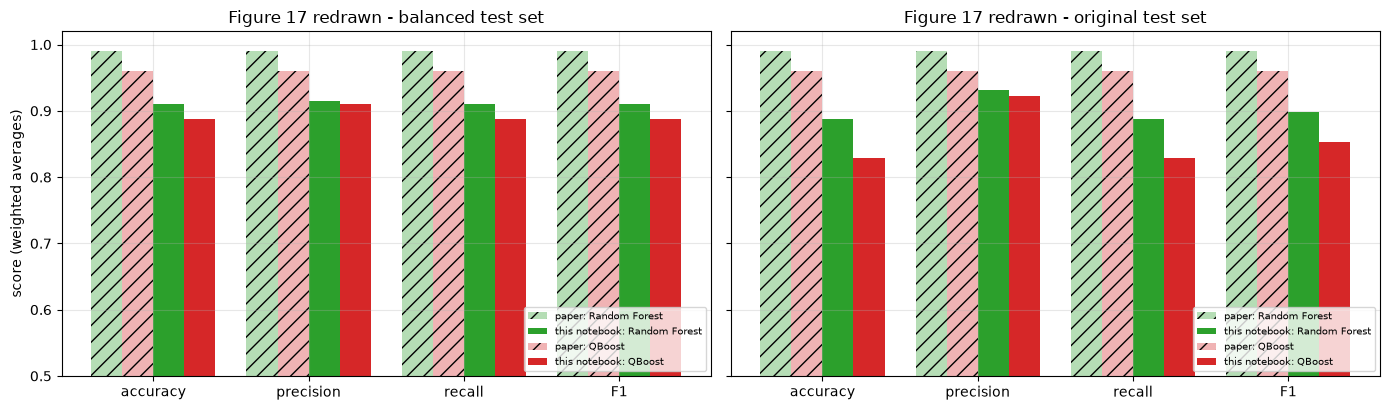

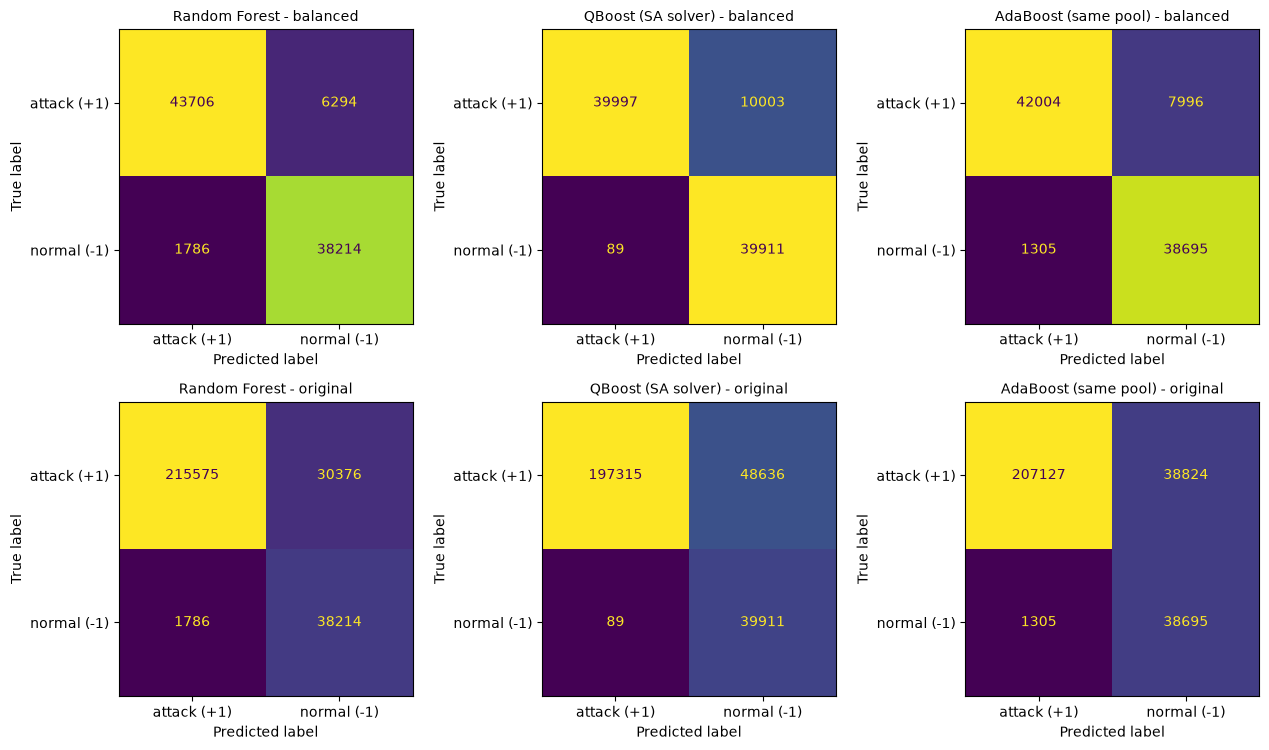

In [13]:
PAPER = {"Random Forest": dict(acc=0.99, prec_w=0.99, rec_w=0.99, f1_w=0.99), "QBoost (SA solver)": dict(acc=0.96, prec_w=0.96, rec_w=0.96, f1_w=0.96)}   # text of Section 6: 99 % / 96 %, 3-point margin on all metrics
mkeys, mnames = ["acc", "prec_w", "rec_w", "f1_w"], ["accuracy", "precision", "recall", "F1"]
agg = res.groupby(["test", "model"])[cols].mean()
agg_sd = res.groupby(["test", "model"])[cols].std().fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, tset in zip(axes, ("balanced", "original")):
    xs = np.arange(4); w = 0.2
    for k, (mdl, col) in enumerate([("Random Forest", "#2ca02c"), ("QBoost (SA solver)", "#d62728")]):
        ax.bar(xs + (k - 1.5) * w, [PAPER[mdl][m] for m in mkeys], w, color=col, alpha=0.35, hatch="//", label=f"paper: {mdl.split(' (')[0]}")
        ax.bar(xs + (k + 0.5) * w, [agg.loc[(tset, mdl), m] for m in mkeys], w, yerr=[agg_sd.loc[(tset, mdl), m] for m in mkeys], color=col, label=f"this notebook: {mdl.split(' (')[0]}")
    ax.set_xticks(xs); ax.set_xticklabels(mnames); ax.set_ylim(0.5, 1.02); ax.set_title(f"Figure 17 redrawn - {tset} test set"); ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("score (weighted averages)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7.6))
for r_, tset in enumerate(("balanced", "original")):
    for c_, mdl in enumerate(["Random Forest", "QBoost (SA solver)", "AdaBoost (same pool)"]):
        p, tb = PRED[mdl]; idx = tb if tset == "balanced" else slice(None)
        cm = confusion_matrix(yte[idx], p[idx], labels=[1, -1])
        ConfusionMatrixDisplay(cm, display_labels=["attack (+1)", "normal (-1)"]).plot(ax=axes[r_, c_], colorbar=False, values_format="d")
        axes[r_, c_].set_title(f"{mdl} - {tset}", fontsize=10); axes[r_, c_].grid(False)
plt.tight_layout(); plt.show()

In [14]:
# Table 1 redrawn: training / prediction time (mean over seeds, whole original test split)
tm = res[res.test == "original"].groupby("model")[["t_train", "t_pred"]].mean()
rf_t, qb_t = tm.loc["Random Forest"], tm.loc["QBoost (SA solver)"]
qb_sa = res[(res.test == "original") & (res.model == "QBoost (SA solver)")][["t_pool", "t_sa"]].mean()
t1 = pd.DataFrame({"Algorithm": ["QBoost (paper, D-Wave)", "Random Forest (paper)", "QBoost (here, SA)", "Random Forest (here)"],
                   "Training time (s)": [554.5, 2667.5, qb_t.t_train, rf_t.t_train], "Prediction time (s)": [2.24, 7.83, qb_t.t_pred, rf_t.t_pred]})
print(t1.round(2).to_string(index=False))
red_tr, red_pr = 1 - qb_t.t_train / rf_t.t_train, 1 - qb_t.t_pred / rf_t.t_pred
print(f"\nQBoost training time is {100*red_tr:.0f} % shorter than Random Forest's (paper: {100*(1-554.5/2667.5):.0f} %); prediction time {100*red_pr:.0f} % shorter (paper: {100*(1-2.24/7.83):.0f} %)")
print(f"QBoost training here = pool (AdaBoost, {qb_sa.t_pool:.1f} s) + QUBO and simulated annealing ({qb_sa.t_sa:.1f} s). The QUBO solve itself is {100*qb_sa.t_sa/qb_t.t_train:.0f} % of it;")
print("in the paper the 554.5 s include the cloud round trip to D-Wave Leap, which a local run cannot reproduce. Training sets also differ (paper: 8.2 M balanced training rows; here: %d)." % res[res.model == "Random Forest"].n_train.iloc[0])

             Algorithm  Training time (s)  Prediction time (s)
QBoost (paper, D-Wave)             554.50                 2.24
 Random Forest (paper)            2667.50                 7.83
     QBoost (here, SA)              47.53                 5.57
  Random Forest (here)              54.22                15.94

QBoost training time is 12 % shorter than Random Forest's (paper: 79 %); prediction time 65 % shorter (paper: 71 %)
QBoost training here = pool (AdaBoost, 26.4 s) + QUBO and simulated annealing (20.6 s). The QUBO solve itself is 43 % of it;
in the paper the 554.5 s include the cloud round trip to D-Wave Leap, which a local run cannot reproduce. Training sets also differ (paper: 8.2 M balanced training rows; here: 31473).


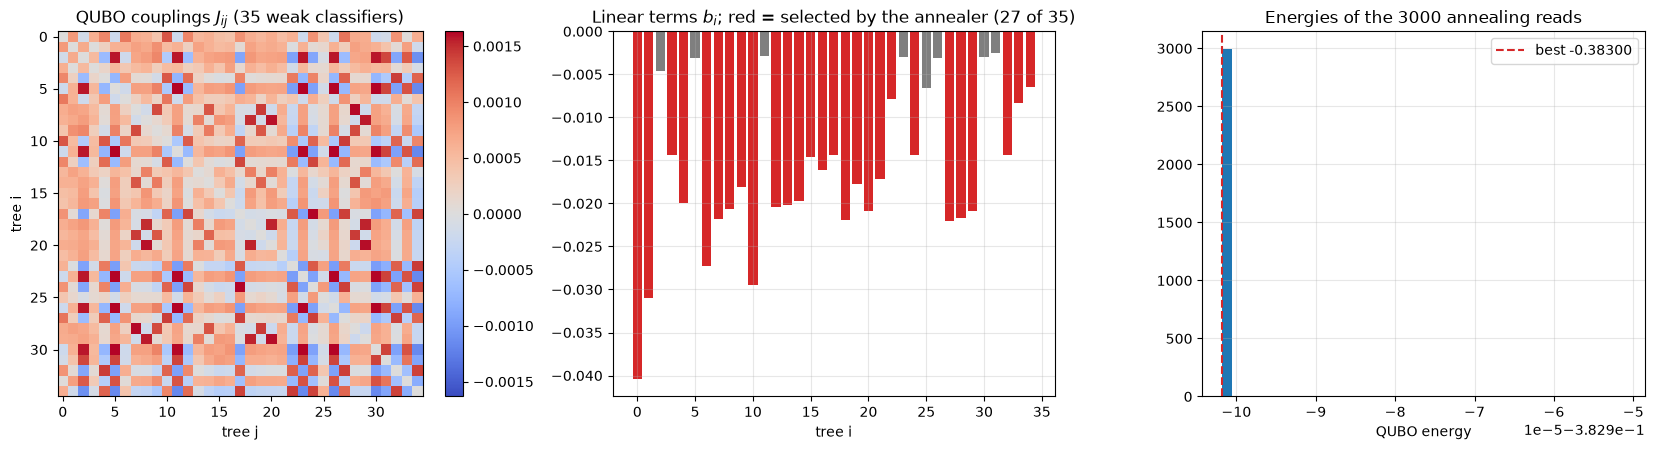

number of trees selected per read (count of reads): {27: 2997, 28: 3}


In [15]:
# The QUBO that QBoost solved (first seed): couplings, linear terms, selected trees, energy spectrum of the 3000 annealing reads
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
im = axes[0].imshow(QB["J"], cmap="coolwarm", vmin=-np.abs(QB["J"]).max(), vmax=np.abs(QB["J"]).max())
axes[0].set_title("QUBO couplings $J_{ij}$ (35 weak classifiers)"); axes[0].set_xlabel("tree j"); axes[0].set_ylabel("tree i"); axes[0].grid(False); plt.colorbar(im, ax=axes[0], fraction=0.046)
sel = QB["w"] > 0.5
axes[1].bar(np.arange(len(QB["b"])), QB["b"], color=np.where(sel, "#d62728", "#7f7f7f"))
axes[1].set_title(f"Linear terms $b_i$; red = selected by the annealer ({int(sel.sum())} of {len(sel)})"); axes[1].set_xlabel("tree i")
axes[2].hist(QB["E"], bins=40, color="#1f77b4"); axes[2].axvline(QB["E"].min(), color="#d62728", ls="--", label=f"best {QB['E'].min():.5f}")
axes[2].set_title(f"Energies of the {len(QB['E'])} annealing reads"); axes[2].set_xlabel("QUBO energy"); axes[2].legend()
plt.tight_layout(); plt.show()
dist = pd.Series(QB["Wall"].sum(1)).value_counts().sort_index()
print("number of trees selected per read (count of reads):", {int(k): int(v) for k, v in dist.items()})
Hte_full = HT_TEST

## 8. Ablations the paper does not report

(a) **lambda sweep**: how many trees QBoost keeps and how accurate it is for other lambda (the pool and the test predictions of the first seed are reused; only the annealing is repeated).
(b) **Number of PCA components** (and no PCA at all) for QBoost and Random Forest on the same capped sample: the paper does not say how much the 13-component reduction costs.
(c) **Duplicate rows**: flows with an exact twin in the training split, and accuracy on test flows with and without a twin.

In [16]:
# (a) lambda sweep on the first seed (pool trained once; Hte_full = scaled weak outputs on the whole test split)
rows = []
Pb13 = D["Pb"][:, :N_PCA]; yb13 = D["yb"]
Htr = np.array([t.predict(Pb13) for t in QB["pool"]], dtype=np.float64) / len(QB["pool"])
for lam in [0.0, 0.01, 0.085, 0.5, 2.0, 10.0]:
    b_, J_ = build_qubo(Htr, yb13.astype(float), lam)
    w_, E_, _ = anneal_qubo(b_, J_, reads=SA_READS, sweeps=SA_SWEEPS, seed=SEED)
    pred = np.where(w_ @ Hte_full >= 0, 1, -1)
    mb = metrics(yte[D["te_bal"]], pred[D["te_bal"]]); mo = metrics(yte, pred)
    rows.append(dict(lam=lam, trees_selected=int(w_.sum()), acc_balanced=round(mb["acc"], 4), f1_att_balanced=round(mb["f1_att"], 4), acc_original=round(mo["acc"], 4)))
lam_tab = pd.DataFrame(rows); print(lam_tab.to_string(index=False)); del Htr
print("\nreading: with this normalisation lambda = 0.085 keeps most trees; a large lambda switches trees off and, once all are off, QBoost predicts the single class '+1' (every flow an attack).")

   lam  trees_selected  acc_balanced  f1_att_balanced  acc_original
 0.000              29        0.8894           0.8897        0.8322
 0.010              29        0.8894           0.8897        0.8322
 0.085              27        0.8879           0.8880        0.8296
 0.500              16        0.8939           0.8983        0.8613
 2.000               0        0.5556           0.7143        0.8601
10.000               0        0.5556           0.7143        0.8601

reading: with this normalisation lambda = 0.085 keeps most trees; a large lambda switches trees off and, once all are off, QBoost predicts the single class '+1' (every flow an attack).


In [17]:
# (b) PCA dimension: QBoost and RF on the same capped sample of the balanced training set, n components or all 45 scaled features (first seed)
ai = stratified_idx(ABL_ROWS, D["yb"], SEED)
Xtr_abl = {"PCA 2": D["Pb"][ai, :2], "PCA 4": D["Pb"][ai, :4], f"PCA {N_PCA} (paper)": D["Pb"][ai, :N_PCA], f"PCA {D['info']['n_pca_threshold']} (0.99 threshold)": D["Pb"][ai, :D["info"]["n_pca_threshold"]], f"no PCA ({Xs_tr.shape[1]} features)": D["Xb"][ai]}
Xte_abl = {"PCA 2": D["Pte"][:, :2], "PCA 4": D["Pte"][:, :4], f"PCA {N_PCA} (paper)": D["Pte"][:, :N_PCA], f"PCA {D['info']['n_pca_threshold']} (0.99 threshold)": D["Pte"][:, :D["info"]["n_pca_threshold"]], f"no PCA ({Xs_tr.shape[1]} features)": Xs_te}
rows = []
for name in Xtr_abl:
    m_ = qboost_fit(Xtr_abl[name], D["yb"][ai], SEED)
    pq, _ = qboost_predict(m_, Xte_abl[name])
    rf_ = RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED).fit(Xtr_abl[name], D["yb"][ai]); pr_ = rf_.predict(Xte_abl[name])
    tb = D["te_bal"]
    rows.append(dict(inputs=name, QBoost_acc_balanced=round(accuracy_score(yte[tb], pq[tb]), 4), RF_acc_balanced=round(accuracy_score(yte[tb], pr_[tb]), 4),
                     QBoost_acc_original=round(accuracy_score(yte, pq), 4), RF_acc_original=round(accuracy_score(yte, pr_), 4), QBoost_trees=int(m_["w"].sum())))
abl_pca = pd.DataFrame(rows); print(f"training rows: {len(ai):,}"); print(abl_pca.to_string(index=False)); del Xtr_abl, Xte_abl

training rows: 10,000
                 inputs  QBoost_acc_balanced  RF_acc_balanced  QBoost_acc_original  RF_acc_original  QBoost_trees
                  PCA 2               0.8762           0.8840               0.8115           0.8610            23
                  PCA 4               0.8741           0.8955               0.8082           0.8711            27
         PCA 13 (paper)               0.8737           0.9041               0.8125           0.8800            28
PCA 16 (0.99 threshold)               0.8844           0.9039               0.8328           0.8797            28
   no PCA (45 features)               0.9553           0.9629               0.9380           0.9538            28


In [18]:
# (c) exact duplicates: do test flows have an identical twin (same 45 scaled features) in the training split?
def row_hash(X):
    return pd.util.hash_pandas_object(pd.DataFrame(np.round(X, 6)), index=False).to_numpy()
h_tr = row_hash(Xs_tr); h_te = row_hash(Xs_te)
twin = np.isin(h_te, h_tr)
print(f"duplicate rows inside the training split: {len(h_tr) - len(np.unique(h_tr)):,} of {len(h_tr):,} ({1 - len(np.unique(h_tr))/len(h_tr):.1%})")
print(f"test flows with an exact twin in the training split: {twin.sum():,} of {len(twin):,} ({twin.mean():.1%})")
for mdl in ("Random Forest", "QBoost (SA solver)"):
    p, _ = PRED[mdl]; ok = p == yte
    print(f"{mdl:22s} accuracy (original test): all {ok.mean():.4f} | with a twin {ok[twin].mean():.4f} | without a twin {ok[~twin].mean():.4f}")
del h_tr, h_te

duplicate rows inside the training split: 262,201 of 1,143,802 (22.9%)
test flows with an exact twin in the training split: 70,463 of 285,951 (24.6%)
Random Forest          accuracy (original test): all 0.8875 | with a twin 0.9999 | without a twin 0.8508
QBoost (SA solver)     accuracy (original test): all 0.8296 | with a twin 0.9995 | without a twin 0.7741


## 9. Side-by-side comparison and verdicts

Rule: a number is "reproduced" if it is within 0.02 of the paper's value (metrics on a 0-1 scale); otherwise "not reached" (ours lower) or "exceeded" (ours higher), with the gap. Time reductions are "reproduced" within 10 percentage
points. The quality claims are judged on the *balanced* test set (the paper's test set is balanced), and the original-distribution values are shown next to them. A claim this setup cannot test is "cannot be checked".

In [19]:
def verdict_num(ours, paper, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")

A = lambda mdl, m, t="balanced": float(agg.loc[(t, mdl), m])
claims = []
for mdl in ("Random Forest", "QBoost (SA solver)"):
    for m, mn in zip(mkeys, mnames):
        claims.append((f"{mdl.split(' (')[0]} {mn} = {PAPER[mdl][m]:.2f} (Fig. 17 / Sec. 6)", PAPER[mdl][m], round(A(mdl, m), 3), verdict_num(A(mdl, m), PAPER[mdl][m]),
                       f"original test: {A(mdl, m, 'original'):.3f}"))
gaps = {m: A("Random Forest", m) - A("QBoost (SA solver)", m) for m in mkeys}
claims.append(("RF - QBoost margin about 3 points on every metric (Sec. 6)", 0.03, round(np.mean(list(gaps.values())), 3),
               "reproduced" if all(abs(g - 0.03) <= 0.02 for g in gaps.values()) else ("not reached (margin smaller)" if np.mean(list(gaps.values())) < 0.01 else "not reached (margin larger)" if np.mean(list(gaps.values())) > 0.05 else "reproduced"),
               "gaps: " + ", ".join(f"{mn} {gaps[m]:+.3f}" for m, mn in zip(mkeys, mnames)) + f"; original test: acc gap {A('Random Forest','acc','original')-A('QBoost (SA solver)','acc','original'):+.3f}"))
claims.append(("QBoost is a viable alternative to RF: both 'comparable' (|gap| <= 0.05 on accuracy)", "comparable", f"gap {gaps['acc']:+.3f}", "reproduced" if abs(gaps["acc"]) <= 0.05 else "not reached", "balanced test"))
claims.append(("QBoost training time about 80 % shorter than RF (Table 1: 554.5 s vs 2667.5 s)", round(1 - 554.5 / 2667.5, 3), round(red_tr, 3),
               "reproduced" if abs(red_tr - (1 - 554.5 / 2667.5)) <= 0.10 else (f"exceeded (+{red_tr-(1-554.5/2667.5):.2f})" if red_tr > 1 - 554.5 / 2667.5 else f"not reached ({red_tr-(1-554.5/2667.5):.2f})"),
               f"here {qb_t.t_train:.1f} s vs {rf_t.t_train:.1f} s on {res[res.model=='Random Forest'].n_train.iloc[0]:,} rows; QUBO solve alone {qb_sa.t_sa:.1f} s"))
claims.append(("QBoost prediction time about 71 % shorter than RF (Table 1: 2.24 s vs 7.83 s)", round(1 - 2.24 / 7.83, 3), round(red_pr, 3),
               "reproduced" if abs(red_pr - (1 - 2.24 / 7.83)) <= 0.10 else (f"exceeded (+{red_pr-(1-2.24/7.83):.2f})" if red_pr > 1 - 2.24 / 7.83 else f"not reached ({red_pr-(1-2.24/7.83):.2f})"),
               f"here {qb_t.t_pred:.2f} s vs {rf_t.t_pred:.2f} s on {len(yte):,} test flows"))
claims.append(("PCA with threshold 0.99 keeps 13 components (Sec. 5.2)", 13, D["info"]["n_pca_threshold"], "reproduced" if D["info"]["n_pca_threshold"] == 13 else f"not reached ({D['info']['n_pca_threshold'] - 13:+d} components)",
               f"on the mirror; the 13 components explain {D['cum'][N_PCA-1]:.4f} of the variance"))
claims.append(("Balanced dataset of 10,257,385 rows (Sec. 5.2, step 6)", 10257385, D["info"]["rows_balanced"], "cannot be checked", "the mirror is a class-capped subsample (benign 14 %, not 2.3 %), so row counts are not comparable"))
claims.append(("QRadar rules detect HTTP-flood DDoS, XSS, SQL injection and port scans; offense after 2 to 3 min (Figs. 8-16)", "-", "-", "cannot be checked", "needs a QRadar VM and packet captures with IP addresses; CICIoT2023 flow features have none"))
claims.append(("Hybrid architecture / dashboard works with D-Wave Leap + QRadar (Figs. 5-6)", "-", "-", "cannot be checked", "software-architecture claim; no D-Wave account, no QRadar, no Angular/Flask/PostgreSQL stack here"))
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 220)
verd = pd.DataFrame(claims, columns=["claim", "paper", "ours", "verdict", "evidence"])
print(verd.verdict.str.split(" ").str[0].value_counts().to_string())
verd

verdict
not           10
reproduced     3
cannot         3


,claim,paper,ours,verdict,evidence
0,Random Forest accuracy = 0.99 (Fig. 17 / Sec. 6),0.99,0.91,not reached (-0.080),original test: 0.888
1,Random Forest precision = 0.99 (Fig. 17 / Sec. 6),0.99,0.915,not reached (-0.075),original test: 0.931
2,Random Forest recall = 0.99 (Fig. 17 / Sec. 6),0.99,0.91,not reached (-0.080),original test: 0.888
3,Random Forest F1 = 0.99 (Fig. 17 / Sec. 6),0.99,0.91,not reached (-0.080),original test: 0.899
4,QBoost accuracy = 0.96 (Fig. 17 / Sec. 6),0.96,0.888,not reached (-0.072),original test: 0.830
5,QBoost precision = 0.96 (Fig. 17 / Sec. 6),0.96,0.91,not reached (-0.050),original test: 0.923
6,QBoost recall = 0.96 (Fig. 17 / Sec. 6),0.96,0.888,not reached (-0.072),original test: 0.830
7,QBoost F1 = 0.96 (Fig. 17 / Sec. 6),0.96,0.888,not reached (-0.072),original test: 0.852
8,RF - QBoost margin about 3 points on every metric (Sec. 6),0.03,0.018,reproduced,"gaps: accuracy +0.022, precision +0.006, recall +0.022, F1 +0.023; original test: acc gap +0.058"
9,QBoost is a viable alternative to RF: both 'comparable' (|gap| <= 0.05 on accuracy),comparable,gap +0.022,reproduced,balanced test


## Reading the paper critically

* **The evaluation is a small part of the paper.** The contribution is an architecture (Figures 5 to 7); the only measured quantities are one pair of accuracy bars and one timing table. The dashboard and the QRadar offenses have no metric,
  so "the validity of the architecture was proven by experiments" rests on a single binary classifier comparison.
* **The balanced test set contains synthetic rows.** SMOTE and under-sampling are applied to the whole dataset before the 80 : 20 split, so synthetic benign flows (interpolations of real ones) land in the test set, and the real benign flows they
  were built from land in training. Scores measured that way are optimistic. Here balancing touches the training split only.
* **Duplicate flows leak across the split.** CICIoT2023 contains many identical flows (see Section 8c). A random split puts twins on both sides, so high accuracy partly measures memorisation; the paper does not de-duplicate.
* **PCA first, then the classifier, costs accuracy.** Section 8b shows how far a 13-component projection limits both QBoost and Random Forest compared with the 45 scaled features; the paper's 99 % for Random Forest is hard to reconcile with
  a PCA-13 input unless the balanced, partly synthetic test set is easy. A reader cannot tell which input the Random Forest received.
* **QBoost is a boosted-tree classifier with a combinatorial pruning step.** Its pool is AdaBoost; the annealer only chooses which of 35 trees vote (with equal weights). Plain AdaBoost on the same pool is as good or better in the tables of Sections 4 to 6,
  so the quality QBoost reaches is a property of the pool, not of quantum annealing. A 35-variable QUBO is solved exactly by brute force on a laptop in milliseconds; the simulated annealer here finds the optimum in nearly every read.
* **The timing claim is not a quantum speed-up.** QBoost's prediction is 35 depth-3 trees; Random Forest's is 100 fully grown trees, so a shorter prediction time (Table 1 redrawn in Section 7) says that a small model is cheaper than a big one.
  QBoost's training here includes fitting the AdaBoost pool, which costs as much as fitting a forest, plus the QUBO solve; the paper's 80 % training-time saving is therefore not seen locally (see the verdict table), and the paper's D-Wave time also contains
  cloud latency and a training set far larger than ours.
* **Which Random Forest?** No hyper-parameters, no feature set and no number of trees are given, nor the averaging of precision/recall/F1 (weighted, to match accuracy = recall in the group's other paper).
* **lambda = 0.085 is not interpretable without the objective's normalisation**, which the paper omits; with a sum-over-samples loss (as in the group's QC-023 notebook) lambda would be negligible, with a mean loss and a per-tree penalty it matters (Section 8a).
* **What does reproduce.** A QBoost classifier built from 35 shallow trees reaches the neighbourhood of a Random Forest's quality at a small fraction of its prediction cost (see the verdict table for the exact margins), and the pre-processing recipe is
  reproducible on public data. The architecture itself, the dashboard and QRadar are outside what a notebook can verify.

## Exercises

1. **Strip the "quantum" away.** Replace the annealer by `w = np.ones(35)` (keep all trees) and by a greedy forward selection. How much accuracy does QBoost's subset selection add over simply averaging all 35 trees, and over AdaBoost's own weights?
2. **Fair timing.** Make Random Forest as small as QBoost's pool (35 trees of depth 3) and recompute the 71 % / 80 % time reductions of Table 1. What is left of the speed advantage?
3. **Un-leak the test set.** Move every test flow that has a twin in the training split (Section 8c) out of the evaluation, or de-duplicate before the split, and rerun the verdict table. How far do QBoost and Random Forest fall?
4. **Reproduce the paper's leakage.** Balance the *whole* dataset (train and test together, with SMOTE as in the paper; raise `SMOTE_RATIO` to 0.3 so that it applies to this mirror) and only then split 80 : 20. How much higher do the scores get than with the clean protocol of this notebook?
5. **Other solvers.** Replace `anneal_qubo` by a greedy single-flip descent, then by exact enumeration of the best 20 trees. Does the selected subset change, and does the accuracy? If you have a D-Wave Leap account, send `b` and `J` to `LeapHybridSampler` (variables are the 35 weights) and compare the energies.